### Nama : Subhan Aprisa S.
### Nim : H061241041
### Mata Kuliah : Kecerdasan Artificial Untuk Geofisika
# **Modul: Menyusun Prompt AI yang Baik untuk Permasalahan Geofisika**

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import hilbert
from scipy.ndimage import gaussian_filter, label, sobel, binary_opening
from scipy.cluster.vq import kmeans2

OUT = os.environ.get("OUT_DIR", "gpr_output")
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(42)
C = 0.2998  # m/ns, kecepatan cahaya


def ricker(t, f):
    a = (np.pi * f * t) ** 2
    return (1 - 2 * a) * np.exp(-a)


def garis(judul):
    print("\n" + "=" * 70)
    print(judul)
    print("=" * 70)


***Prompt 1: Analisis Hiperbola Difraksi (Deteksi Utilitas Bawah Tanah)***

Role
Anda berperan sebagai seorang Geophysicist Near Surface yang memiliki keahlian dalam metode Ground Penetrating Radar (GPR), khususnya analisis hiperbola difraksi, estimasi kecepatan gelombang elektromagnetik, serta deteksi objek buatan di bawah permukaan seperti pipa dan kabel.

Task
Lakukan analisis terhadap radargram untuk mengidentifikasi hiperbola difraksi yang berasal dari objek bawah permukaan. Analisis mencakup pengenalan bentuk dan posisi apeks hiperbola, estimasi kecepatan gelombang elektromagnetik melalui pencocokan kurva hiperbola, penentuan kedalaman objek, serta pertimbangan kemungkinan jenis objek berdasarkan karakteristik refleksinya.

Context
Survei GPR dilakukan pada area permukiman yang diduga memiliki jaringan utilitas bawah tanah, seperti pipa air atau kabel listrik, yang tidak tercatat dengan jelas dalam peta. Pengukuran dilakukan menggunakan antena berfrekuensi tinggi dengan lintasan tegak lurus terhadap perkiraan arah utilitas. Data radargram kemudian diproses agar hiperbola difraksi lebih mudah dikenali dan dianalisis.

Input
Data yang tersedia berupa radargram hasil pengukuran, panjang dan arah lintasan, frekuensi antena, rentang waktu tempuh (time window), interval antar-trace, serta informasi kondisi permukaan dan jenis tanah di lokasi survei. Apabila tersedia, gunakan hasil pengolahan seperti background removal, gain, dan filtering sebagai dasar interpretasi.

Constraints
Jangan menentukan jenis material atau fungsi objek hanya berdasarkan bentuk hiperbola. Kedalaman tidak boleh dihitung tanpa dasar kecepatan gelombang elektromagnetik yang dapat dipertanggungjawabkan. Jangan menganggap setiap hiperbola sebagai utilitas karena batu, akar pohon, atau heterogenitas tanah juga dapat menghasilkan pola serupa. Bedakan dengan jelas antara data pengukuran, hasil perhitungan, asumsi, dan interpretasi.

Output
Sajikan hasil dalam bentuk narasi akademik yang mengalir dan tidak menggunakan tabel, poin, maupun daftar. Uraikan karakteristik hiperbola yang teramati, proses estimasi kecepatan dan kedalaman, kemungkinan keberadaan serta orientasi utilitas, dan tingkat keyakinan interpretasi. Jelaskan pula bagian data yang masih memiliki ketidakpastian dan data tambahan yang diperlukan untuk memastikan hasil.


1. ANALISIS HIPERBOLA DIFRAKSI - DETEKSI UTILITAS
Target 1: x0 = 2.00 m | kedalaman = 0.45 m (+/-0.001) | v = 0.100 m/ns (+/-0.0001) | eps_r = 9.0
          nilai sebenarnya: x0=2.0 m, d=0.45 m, v=0.1 m/ns
Target 2: x0 = 4.30 m | kedalaman = 0.81 m (+/-0.002) | v = 0.101 m/ns (+/-0.0002) | eps_r = 8.8
          nilai sebenarnya: x0=4.3 m, d=0.8 m, v=0.1 m/ns


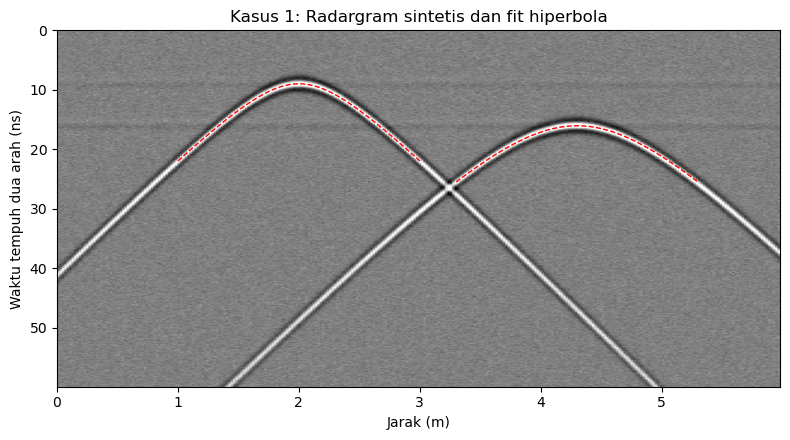

In [4]:
def kasus1():
    garis("1. ANALISIS HIPERBOLA DIFRAKSI - DETEKSI UTILITAS")
    f = 0.4                      # GHz (400 MHz)
    dx = 0.02                    # m
    x = np.arange(0, 6, dx)
    t = np.arange(0, 60, 0.1)    # ns
    v_true = 0.10                # m/ns (tanah lembap)
    targets = [(2.0, 0.45), (4.3, 0.80)]  # (x0, kedalaman)
    rg = np.zeros((len(t), len(x)))
    for x0, d in targets:
        tt = 2 * np.sqrt(d**2 + (x - x0) ** 2) / v_true
        amp = 1.0 / (1 + 0.4 * np.abs(x - x0))
        for i, xi in enumerate(x):
            rg[:, i] += amp[i] * ricker(t - tt[i], f)
    rg += 0.05 * rng.standard_normal(rg.shape)
    rg_bg = rg - rg.mean(axis=1, keepdims=True)  # background removal

    def hip(xx, x0, d, v):
        return 2 * np.sqrt(d**2 + (xx - x0) ** 2) / v

    hasil = []
    for k, (x0, d) in enumerate(targets):
        # tebakan awal kasar -> picking -> fit -> picking ulang di sekitar kurva hasil fit
        p = np.array([x0 + 0.05, d * 1.1, 0.12])
        for _ in range(4):
            guess = hip(x, *p)
            xs, ts = [], []
            for i, xi in enumerate(x):
                if abs(xi - p[0]) > 0.8:
                    continue
                m = (t > guess[i] - 2) & (t < guess[i] + 2)
                j = np.argmax(rg_bg[m, i])
                xs.append(xi)
                ts.append(t[m][j])
            xs, ts = np.array(xs), np.array(ts)
            p, cov = curve_fit(hip, xs, ts, p0=p)
        err = np.sqrt(np.diag(cov))
        hasil.append(p)
        print(f"Target {k+1}: x0 = {p[0]:.2f} m | kedalaman = {p[1]:.2f} m "
              f"(+/-{err[1]:.3f}) | v = {p[2]:.3f} m/ns (+/-{err[2]:.4f}) "
              f"| eps_r = {(C/p[2])**2:.1f}")
        print(f"          nilai sebenarnya: x0={x0} m, d={d} m, v={v_true} m/ns")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.imshow(rg_bg, aspect="auto", cmap="gray", extent=[x[0], x[-1], t[-1], t[0]],
              vmin=-0.6, vmax=0.6)
    for p in hasil:
        xx = np.linspace(p[0] - 1, p[0] + 1, 200)
        ax.plot(xx, hip(xx, *p), "r--", lw=1)
    ax.set_xlabel("Jarak (m)"); ax.set_ylabel("Waktu tempuh dua arah (ns)")
    ax.set_title("Kasus 1: Radargram sintetis dan fit hiperbola")
    fig.tight_layout(); fig.savefig(f"{OUT}/kasus1_hiperbola.png", dpi=130); plt.show()


kasus1()


***Prompt 2: Analisis Atribut Amplitudo dan Atenuasi (Identifikasi Rongga/Karst)***

Role
Anda berperan sebagai seorang Geophysicist Engineering yang berpengalaman dalam metode Ground Penetrating Radar (GPR), analisis atribut amplitudo sinyal, karakteristik atenuasi gelombang elektromagnetik, serta identifikasi rongga dan zona lemah pada batuan karbonat.

Task
Analisis perubahan amplitudo dan atenuasi sinyal pada data GPR untuk mengidentifikasi kemungkinan keberadaan rongga atau zona pelapukan bawah permukaan. Analisis mencakup pengamatan zona amplitudo kuat dan lemah, perubahan polaritas refleksi, hilangnya sinyal pada kedalaman tertentu, serta hubungannya dengan kondisi geologi daerah karst.

Context
Survei GPR dilakukan pada lahan rencana pembangunan yang berada di wilayah dengan batuan gamping dan indikasi karst permukaan. Pengukuran dilakukan menggunakan antena berfrekuensi menengah sepanjang beberapa lintasan paralel untuk mengetahui apakah terdapat rongga atau zona lemah yang berpotensi membahayakan struktur bangunan.

Input
Data yang diberikan berupa radargram beberapa lintasan, posisi lintasan, frekuensi antena, parameter akuisisi, atribut amplitudo atau envelope apabila tersedia, serta informasi geologi, kondisi tanah penutup, dan kondisi kelembapan permukaan daerah penelitian.

Constraints
Jangan menyimpulkan adanya rongga hanya berdasarkan satu zona amplitudo kuat atau satu polaritas terbalik. Jangan mengabaikan kemungkinan bahwa atenuasi tinggi disebabkan oleh tanah lempung atau kandungan air. Ukuran, isi, dan kedalaman rongga tidak boleh ditentukan tanpa dukungan data kecepatan dan pola refleksi yang konsisten antarlintasan.

Output
Sajikan hasil dalam bentuk narasi akademik yang berkesinambungan tanpa tabel, poin, ataupun daftar. Jelaskan pola amplitudo dan atenuasi yang teramati, zona yang dicurigai sebagai rongga atau area lemah, kesesuaiannya dengan kondisi geologi karst, alternatif penyebab lain dari anomali, serta tingkat ketidakpastian dan rekomendasi verifikasi lapangan yang diperlukan.


2. ATRIBUT AMPLITUDO DAN ATENUASI - IDENTIFIKASI RONGGA/KARST
Ambang RMS (mean+1.5 sd) = 0.071
Zona anomali 1: x = 4.55-5.95 m | lebar = 1.40 m | polaritas atap = terbalik (negatif) | kedalaman atap = 2.34 m (v=0.09 m/ns)
Rasio energi reflektor dalam (67-73 ns) di bawah anomali / di luar = 0.47


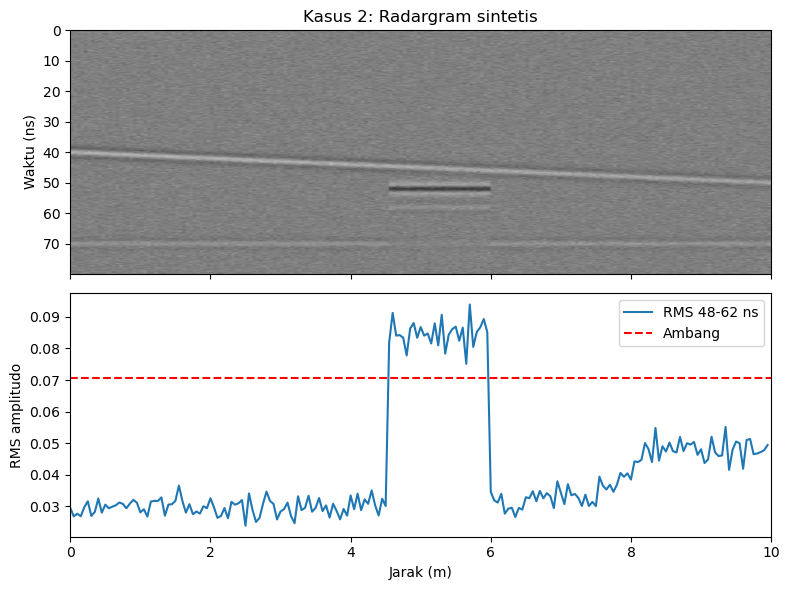

In [5]:
def kasus2():
    garis("2. ATRIBUT AMPLITUDO DAN ATENUASI - IDENTIFIKASI RONGGA/KARST")
    f = 0.25
    x = np.arange(0, 10, 0.05)
    t = np.arange(0, 80, 0.2)
    v = 0.09
    rg = np.zeros((len(t), len(x)))
    # reflektor batas tanah-gamping (miring ringan)
    t_ref = 40 + 1.0 * x
    # rongga: x 4.5-6.0, atap pada t ~ 52 ns
    rongga = (x > 4.5) & (x < 6.0)
    for i in range(len(x)):
        rg[:, i] += 0.8 * ricker(t - t_ref[i], f)
        rg[:, i] += 0.9 * ricker(t - 70, f)      # reflektor dalam (batas gamping padat)
        if rongga[i]:
            rg[:, i] += -1.6 * ricker(t - 52, f)       # polaritas terbalik (udara)
            rg[:, i] += 0.5 * ricker(t - 58, f)        # dasar rongga
    atenuasi = np.exp(-0.035 * t)[:, None]
    rg *= atenuasi
    # bayangan di bawah rongga (energi berkurang)
    shadow = np.where(rongga[None, :] & (t[:, None] > 60), 0.35, 1.0)
    rg *= shadow
    rg += 0.03 * rng.standard_normal(rg.shape)

    env = np.abs(hilbert(rg, axis=0))
    env_s = gaussian_filter(env, sigma=(3, 2))
    # RMS amplitudo pada jendela 48-62 ns
    w = (t > 48) & (t < 62)
    rms = np.sqrt((rg[w] ** 2).mean(axis=0))
    ambang = rms.mean() + 1.5 * rms.std()
    anom = rms > ambang
    lab, n = label(anom)
    print(f"Ambang RMS (mean+1.5 sd) = {ambang:.3f}")
    for k in range(1, n + 1):
        idx = np.where(lab == k)[0]
        xa, xb = x[idx[0]], x[idx[-1]]
        i0 = idx[len(idx) // 2]
        # polaritas pada atap (t ~ 52 ns)
        tw = (t > 50) & (t < 54)
        j = np.argmax(np.abs(rg[tw, i0]))
        pol = np.sign(rg[tw, i0][j])
        t_atap = t[tw][j]
        print(f"Zona anomali {k}: x = {xa:.2f}-{xb:.2f} m | lebar = {xb-xa:.2f} m | "
              f"polaritas atap = {'terbalik (negatif)' if pol < 0 else 'normal (positif)'} "
              f"| kedalaman atap = {v*t_atap/2:.2f} m (v={v} m/ns)")
    # rasio energi di bawah rongga vs luar
    wb = (t > 67) & (t < 73)
    e_in = (env[wb][:, rongga] ** 2).mean()
    e_out = (env[wb][:, ~rongga] ** 2).mean()
    print(f"Rasio energi reflektor dalam (67-73 ns) di bawah anomali / di luar = {e_in/e_out:.2f}")
    fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax[0].imshow(rg, aspect="auto", cmap="gray", extent=[0, 10, t[-1], t[0]], vmin=-0.5, vmax=0.5)
    ax[0].set_ylabel("Waktu (ns)"); ax[0].set_title("Kasus 2: Radargram sintetis")
    ax[1].plot(x, rms, label="RMS 48-62 ns"); ax[1].axhline(ambang, color="r", ls="--", label="Ambang")
    ax[1].set_xlabel("Jarak (m)"); ax[1].set_ylabel("RMS amplitudo"); ax[1].legend()
    fig.tight_layout(); fig.savefig(f"{OUT}/kasus2_amplitudo.png", dpi=130); plt.show()


kasus2()


***Prompt 3: Analisis Radar Facies (Stratigrafi Sedimen Dangkal)***

Role
Anda berperan sebagai seorang Geophysicist Sedimentology yang memiliki kompetensi dalam metode Ground Penetrating Radar (GPR), analisis radar facies, interpretasi radar stratigrafi, serta pemahaman mengenai struktur sedimen dan lingkungan pengendapan dangkal.

Task
Lakukan interpretasi radar facies pada radargram untuk mengidentifikasi pola perlapisan sedimen bawah permukaan. Analisis mencakup pengenalan terminasi reflektor seperti onlap, downlap, toplap, dan truncation, penentuan batas antar-unit radar, serta pengelompokan pola refleksi berdasarkan kontinuitas, kemiringan, dan konfigurasinya.

Context
Survei GPR dilakukan pada area dataran aluvial dan tepian sungai untuk memahami susunan endapan sedimen dangkal dan kemungkinan keberadaan paleo-channel. Pengukuran dilakukan menggunakan antena berfrekuensi rendah hingga menengah agar mampu menembus lapisan sedimen dengan resolusi yang memadai. Hasil radargram digunakan sebagai pendukung pemahaman sejarah pengendapan daerah tersebut.

Input
Data yang tersedia berupa radargram lintasan panjang, koreksi topografi apabila ada, frekuensi antena, kecepatan gelombang yang digunakan, hasil migrasi atau filtering apabila tersedia, serta data singkapan, bor tangan, atau informasi geologi daerah penelitian.

Constraints
Jangan menentukan lingkungan pengendapan hanya berdasarkan pola reflektor tanpa dukungan data geologi. Jangan menganggap semua reflektor miring sebagai struktur sedimen primer karena dapat dipengaruhi oleh artefak pengolahan atau topografi. Hindari penentuan litologi secara pasti dari radargram saja tanpa data pembanding.

Output
Sajikan hasil dalam bentuk narasi akademik yang mengalir tanpa tabel, poin, maupun daftar. Uraikan unit radar facies yang dapat dibedakan, karakter refleksi tiap unit, hubungan antar-unit, kemungkinan interpretasi lingkungan pengendapan, serta keterbatasan interpretasi dan data pendukung yang masih dibutuhkan.


3. ANALISIS RADAR FACIES - STRATIGRAFI SEDIMEN DANGKAL
Radar facies A: rata-rata t =  57.1 ns | |kemiringan| median = 0.20 ns/m | koherensi = 0.99 | piksel = 22.4%
Radar facies B: rata-rata t =  81.0 ns | |kemiringan| median = 1.10 ns/m | koherensi = 0.91 | piksel = 23.1%
Radar facies C: rata-rata t = 100.7 ns | |kemiringan| median = 1.18 ns/m | koherensi = 0.99 | piksel = 11.8%
Radar facies D: rata-rata t = 131.9 ns | |kemiringan| median = 0.25 ns/m | koherensi = 0.40 | piksel = 42.7%
Catatan: kemiringan tinggi + koherensi tinggi -> kandidat cross-bedding;
         koherensi rendah -> kandidat fasies kacau/hummocky.


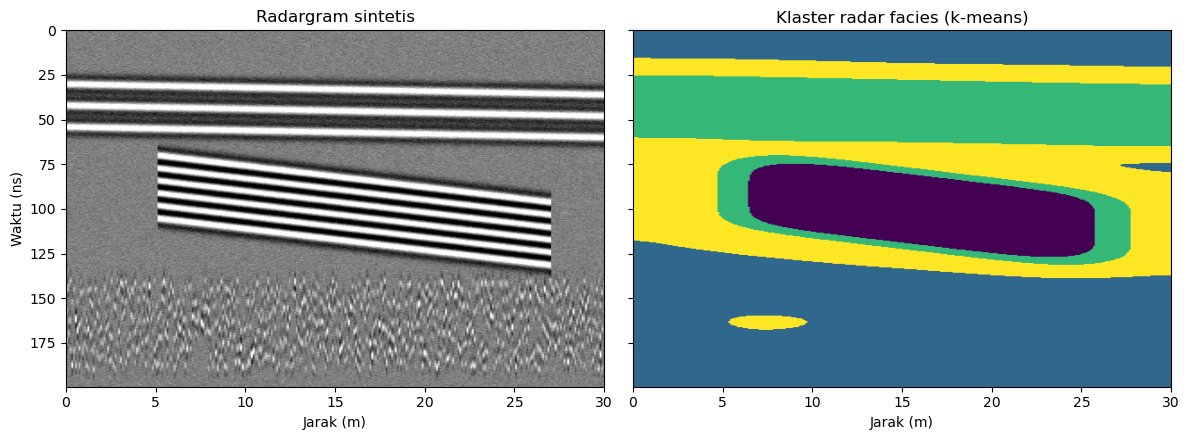

In [6]:
def kasus3():
    garis("3. ANALISIS RADAR FACIES - STRATIGRAFI SEDIMEN DANGKAL")
    f = 0.1
    x = np.arange(0, 30, 0.1)
    t = np.arange(0, 200, 0.5)
    rg = np.zeros((len(t), len(x)))
    # Unit A (atas): reflektor sub-horizontal menerus
    for t0 in (30, 42, 54):
        for i in range(len(x)):
            rg[:, i] += 0.7 * ricker(t - t0 - 0.2 * x[i], f)
    # Unit B (tengah): reflektor miring (cross-bedding) 15-27 m
    for k, t0 in enumerate(range(70, 112, 7)):
        for i in range(len(x)):
            if 5 < x[i] < 27:
                rg[:, i] += 0.8 * ricker(t - (t0 + 1.2 * (x[i] - 5)), f)
    # Unit C (bawah): kacau / hummocky
    for i in range(len(x)):
        for _ in range(4):
            tc = rng.uniform(140, 190)
            rg[:, i] += 0.35 * rng.uniform(0.3, 1) * ricker(t - tc, f)
    rg += 0.04 * rng.standard_normal(rg.shape)
    env = np.abs(hilbert(rg, axis=0))
    env_s = gaussian_filter(env, sigma=(2, 2))
    # tensor struktur -> kemiringan lokal & koherensi
    g = gaussian_filter(rg, 1.0)
    gy = sobel(g, axis=0); gx = sobel(g, axis=1)
    sig = (10, 30)   # jendela tensor ~5 ns x 3 m
    sxx = gaussian_filter(gx * gx, sig); syy = gaussian_filter(gy * gy, sig)
    sxy = gaussian_filter(gx * gy, sig)
    koh = np.sqrt((sxx - syy) ** 2 + 4 * sxy**2) / (sxx + syy + 1e-12)   # koherensi orientasi
    dt_s, dx_s = t[1] - t[0], x[1] - x[0]
    dip_ns_per_m = np.clip(-sxy / (syy + 1e-12) * dt_s / dx_s, -10, 10)  # kemiringan reflektor (ns/m)
    T = np.repeat(t[:, None], len(x), axis=1)
    amp_n = gaussian_filter(env, (10, 30)); amp_n = amp_n / amp_n.max()
    fit = np.stack([T.ravel() / T.max() * 0.5,
                    np.abs(dip_ns_per_m).ravel(),
                    koh.ravel() * 2,
                    amp_n.ravel() * 4], axis=1)
    cent, lbl = kmeans2(fit, 4, minit="++", seed=0)
    lbl = lbl.reshape(rg.shape)
    mean_t = np.array([T[lbl == k].mean() for k in range(4)])
    urut = np.argsort(mean_t)
    for r, k in enumerate(urut):
        m = lbl == k
        print(f"Radar facies {chr(65+r)}: rata-rata t = {T[m].mean():5.1f} ns | "
              f"|kemiringan| median = {np.median(np.abs(dip_ns_per_m[m])):4.2f} ns/m | "
              f"koherensi = {koh[m].mean():.2f} | piksel = {m.mean()*100:4.1f}%")
    print("Catatan: kemiringan tinggi + koherensi tinggi -> kandidat cross-bedding;")
    print("         koherensi rendah -> kandidat fasies kacau/hummocky.")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    ax[0].imshow(rg, aspect="auto", cmap="gray", extent=[0, 30, t[-1], t[0]], vmin=-0.5, vmax=0.5)
    ax[0].set_title("Radargram sintetis"); ax[0].set_xlabel("Jarak (m)"); ax[0].set_ylabel("Waktu (ns)")
    ax[1].imshow(lbl, aspect="auto", cmap="viridis", extent=[0, 30, t[-1], t[0]])
    ax[1].set_title("Klaster radar facies (k-means)"); ax[1].set_xlabel("Jarak (m)")
    fig.tight_layout(); fig.savefig(f"{OUT}/kasus3_radar_facies.png", dpi=130); plt.show()


kasus3()


***Prompt 4: Analisis Kecepatan CMP/WARR (Ketebalan Perkerasan dan Kadar Air)***

Role
Anda berperan sebagai seorang Geophysicist Civil Engineering yang menguasai metode Ground Penetrating Radar (GPR), analisis kecepatan menggunakan konfigurasi Common Mid Point (CMP) dan Wide Angle Reflection and Refraction (WARR), serta hubungan konstanta dielektrik dengan kondisi material perkerasan jalan.

Task
Analisis data GPR konfigurasi CMP atau WARR untuk menentukan kecepatan gelombang elektromagnetik pada lapisan bawah permukaan, kemudian gunakan hasil tersebut untuk memperkirakan ketebalan lapisan perkerasan jalan dan kondisi kandungan air pada lapisan dasar. Analisis mencakup pengamatan pola reflektor terhadap perubahan jarak antena, penentuan kecepatan, dan perhitungan konstanta dielektrik relatif.

Context
Survei GPR dilakukan pada ruas jalan yang mengalami penurunan permukaan dan retakan untuk mengetahui ketebalan lapisan aspal dan pondasi serta indikasi masuknya air ke dalam lapisan bawah. Pengukuran dilakukan pada beberapa titik dengan variasi jarak antara antena pemancar dan penerima, selain lintasan biasa sepanjang badan jalan.

Input
Data yang diberikan berupa radargram CMP atau WARR, jarak antar-antena pada setiap pengukuran, frekuensi antena, waktu tempuh refleksi utama, data ketebalan dari bor inti atau galian uji apabila tersedia, serta informasi kondisi cuaca dan kelembapan saat pengukuran.

Constraints
Kecepatan tidak boleh diasumsikan seragam untuk seluruh lapisan tanpa dasar data. Nilai konstanta dielektrik tidak boleh langsung dianggap sebagai kadar air pasti tanpa mempertimbangkan jenis material. Jangan menetapkan kerusakan struktural hanya dari satu titik pengukuran. Bedakan nilai hasil pengukuran, hasil perhitungan, dan interpretasi kondisi lapisan.

Output
Sajikan hasil dalam bentuk narasi akademik yang berkesinambungan tanpa tabel, poin, ataupun daftar. Jelaskan cara kecepatan diperoleh dari pola data, perkiraan ketebalan tiap lapisan perkerasan, indikasi kondisi kelembapan lapisan bawah, kesesuaiannya dengan kondisi kerusakan jalan, serta tingkat ketidakpastian hasil dan kebutuhan validasi dengan data lapangan.


4. ANALISIS KECEPATAN CMP/WARR - PERKERASAN JALAN
Reflektor 1: t0 = 2.020 ns | v_rms = 0.1201 m/ns | R^2 (t^2-x^2) = 0.9999
Reflektor 2: t0 = 9.390 ns | v_rms = 0.1009 m/ns | R^2 (t^2-x^2) = 0.9999

Hasil interval (Dix):
  Aspal   : v = 0.1201 m/ns | eps_r =  6.23 | tebal =  12.1 cm (model: v=0.12, tebal=12 cm)
  Pondasi : v = 0.0949 m/ns | eps_r =  9.98 | tebal =  35.0 cm (model: v=0.095, tebal=35 cm)
Catatan: eps_r pondasi lebih tinggi dari aspal -> indikasi kelembapan lebih besar,
         tetapi kadar air pasti butuh kalibrasi dengan sampel/bor inti.


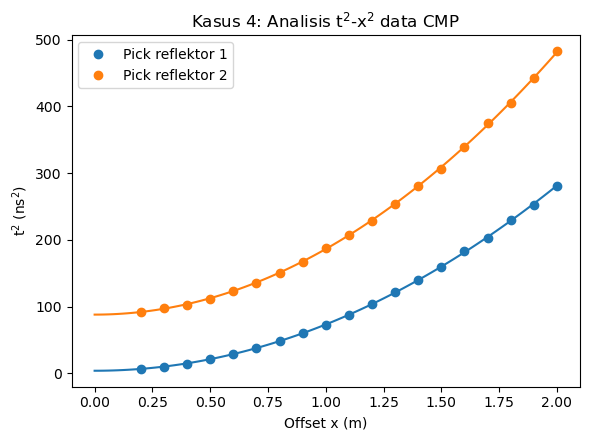

In [7]:
def kasus4():
    garis("4. ANALISIS KECEPATAN CMP/WARR - PERKERASAN JALAN")
    # model: aspal 0.12 m (v=0.12), pondasi 0.35 m (v=0.095), tanah dasar di bawah
    h = np.array([0.12, 0.35]); v = np.array([0.12, 0.095])
    t0 = 2 * np.cumsum(h / v)                       # t0 kumulatif (ns)
    vrms = np.sqrt(np.cumsum(v**2 * (2 * h / v)) / t0)
    offset = np.arange(0.2, 2.01, 0.1)              # m (jarak antar-antena)
    picks = {}
    for k in range(2):
        tt = np.sqrt(t0[k] ** 2 + offset**2 / vrms[k] ** 2)
        picks[k] = tt + 0.04 * rng.standard_normal(len(offset))
    est = []
    for k in range(2):
        A = np.vstack([np.ones_like(offset), offset**2]).T
        coef, res, *_ = np.linalg.lstsq(A, picks[k] ** 2, rcond=None)
        t0e = np.sqrt(coef[0]); vr = 1 / np.sqrt(coef[1])
        pred = A @ coef
        r2 = 1 - np.sum((picks[k] ** 2 - pred) ** 2) / np.sum((picks[k] ** 2 - np.mean(picks[k] ** 2)) ** 2)
        est.append((t0e, vr, r2))
        print(f"Reflektor {k+1}: t0 = {t0e:.3f} ns | v_rms = {vr:.4f} m/ns | R^2 (t^2-x^2) = {r2:.4f}")
    # Dix
    (t01, vr1, _), (t02, vr2, _) = est
    v1 = vr1
    v2 = np.sqrt((vr2**2 * t02 - vr1**2 * t01) / (t02 - t01))
    d1 = v1 * t01 / 2
    d2 = v2 * (t02 - t01) / 2
    print("\nHasil interval (Dix):")
    for nama, vv, dd, vt, ht in (("Aspal", v1, d1, v[0], h[0]), ("Pondasi", v2, d2, v[1], h[1])):
        print(f"  {nama:8s}: v = {vv:.4f} m/ns | eps_r = {(C/vv)**2:5.2f} | tebal = {dd*100:5.1f} cm "
              f"(model: v={vt}, tebal={ht*100:.0f} cm)")
    print("Catatan: eps_r pondasi lebih tinggi dari aspal -> indikasi kelembapan lebih besar,")
    print("         tetapi kadar air pasti butuh kalibrasi dengan sampel/bor inti.")
    fig, ax = plt.subplots(figsize=(6, 4.5))
    xx = np.linspace(0, offset.max(), 100)
    for k, c in zip(range(2), ("tab:blue", "tab:orange")):
        ax.plot(offset, picks[k] ** 2, "o", color=c, label=f"Pick reflektor {k+1}")
        ax.plot(xx, est[k][0] ** 2 + xx**2 / est[k][1] ** 2, "-", color=c)
    ax.set_xlabel("Offset x (m)"); ax.set_ylabel("t$^2$ (ns$^2$)")
    ax.set_title("Kasus 4: Analisis t$^2$-x$^2$ data CMP"); ax.legend()
    fig.tight_layout(); fig.savefig(f"{OUT}/kasus4_cmp.png", dpi=130); plt.show()


kasus4()


***Prompt 5: Analisis Time-Slice 3D GPR (Survei Arkeologi)***

Role
Anda berperan sebagai seorang Geophysicist Archaeology yang berpengalaman dalam metode Ground Penetrating Radar (GPR) tiga dimensi, pembuatan dan interpretasi time-slice atau depth-slice, serta identifikasi struktur tertanam seperti fondasi, dinding, dan ruang bawah tanah.

Task
Lakukan interpretasi terhadap rangkaian time-slice atau depth-slice hasil survei GPR grid untuk mengidentifikasi pola anomali yang mungkin berkaitan dengan struktur buatan manusia. Analisis mencakup perubahan pola anomali pada kedalaman berbeda, kontinuitas dan orientasi anomali dalam arah horizontal, serta hubungan antar-anomali untuk membentuk gambaran tata letak bawah permukaan.

Context
Survei GPR dilakukan pada lahan terbuka yang diduga merupakan lokasi peninggalan bangunan kuno. Pengukuran dilakukan dengan lintasan paralel berjarak rapat membentuk grid agar data dapat diolah menjadi model tiga dimensi. Hasil pengolahan digunakan untuk menentukan lokasi penggalian arkeologi yang paling menjanjikan tanpa merusak situs.

Input
Data yang tersedia berupa radargram seluruh lintasan grid, jarak antar-lintasan, ukuran area survei, frekuensi antena, kecepatan gelombang yang digunakan, peta time-slice atau depth-slice pada beberapa interval kedalaman, serta informasi sejarah dan kondisi permukaan situs.

Constraints
Jangan menyimpulkan suatu anomali sebagai bangunan kuno tanpa mempertimbangkan kontinuitas dan bentuk anomali pada beberapa kedalaman. Hindari menganggap anomali linier sebagai dinding karena dapat berasal dari akar, saluran alami, atau bekas aktivitas modern. Denah dan kedalaman struktur tidak boleh ditetapkan pasti tanpa dukungan kalibrasi kecepatan dan data pembanding.

Output
Sajikan hasil dalam bentuk narasi akademik yang mengalir tanpa tabel, poin, maupun daftar. Uraikan perubahan pola anomali pada tiap rentang kedalaman, anomali yang paling layak diduga sebagai struktur tertanam, kemungkinan tata letak bawah permukaan, penjelasan alternatif terhadap anomali tersebut, serta tingkat keyakinan interpretasi dan rekomendasi lokasi verifikasi.


5. ANALISIS TIME-SLICE 3D GPR - SURVEI ARKEOLOGI
Ambang amplitudo (mean+2.5 sd) = 0.061

Slice t= 4.0 ns (z~0.20 m): piksel > ambang =   19 | segmen horizontal = 0 | segmen vertikal = 0 | bbox linier: -
Slice t=10.0 ns (z~0.50 m): piksel > ambang =  236 | segmen horizontal = 2 | segmen vertikal = 2 | bbox linier: x  4.8-10.5 m, y  3.5- 9.2 m
Slice t=16.0 ns (z~0.80 m): piksel > ambang =  209 | segmen horizontal = 2 | segmen vertikal = 2 | bbox linier: x  4.8-10.5 m, y  3.5- 9.2 m
Slice t=24.0 ns (z~1.20 m): piksel > ambang =    0 | segmen horizontal = 0 | segmen vertikal = 0 | bbox linier: -


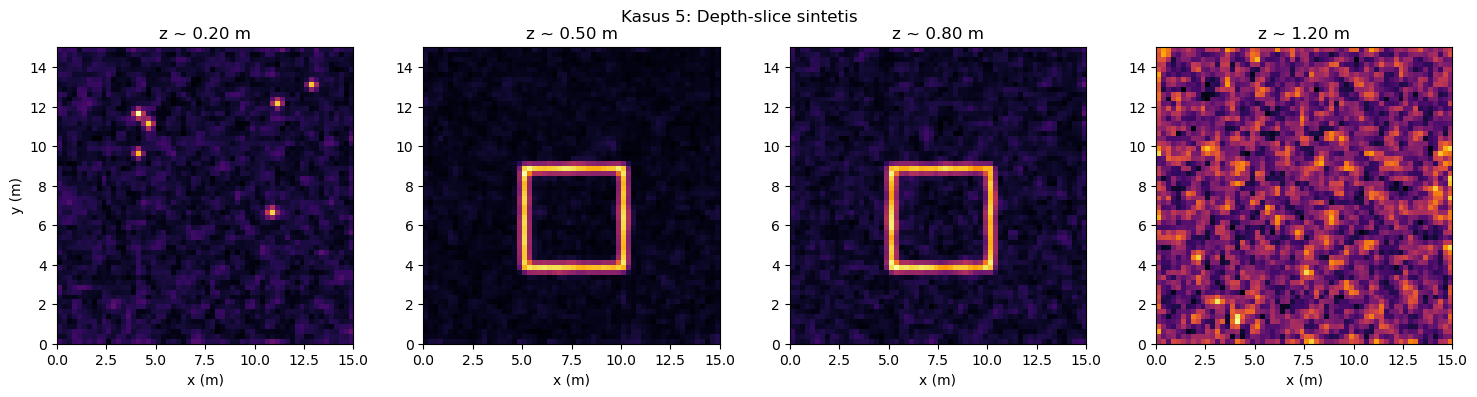


Tumpang tindih struktur linier slice 0,50 m dan 0,80 m (IoU) = 0.75
Catatan: anomali yang muncul di satu kedalaman saja (dangkal, titik) -> kandidat akar/benda modern;
         anomali linier membentuk persegi dan menerus di beberapa slice -> kandidat fondasi/dinding.


In [8]:
def kasus5():
    garis("5. ANALISIS TIME-SLICE 3D GPR - SURVEI ARKEOLOGI")
    nx, ny, nt = 60, 60, 80
    dxy = 0.25                               # m, jarak lintasan & trace
    v = 0.10; dt = 0.5                       # m/ns, ns
    vol = 0.05 * rng.standard_normal((nt, ny, nx))
    f = 0.4
    t = np.arange(nt) * dt
    # dinding kuno: persegi panjang x 20-40 (kolom), y 15-35 (baris), puncak pada t=10 ns (0.50 m)
    wall = np.zeros((ny, nx), bool)
    wall[15, 20:41] = wall[35, 20:41] = True
    wall[15:36, 20] = wall[15:36, 40] = True
    for j in range(ny):
        for i in range(nx):
            if wall[j, i]:
                vol[:, j, i] += 0.9 * ricker(t - 10, f)
                vol[:, j, i] += 0.5 * ricker(t - 16, f)
    # akar pohon / anomali acak dangkal (hanya dangkal)
    for _ in range(6):
        j, i = rng.integers(5, 55, 2)
        vol[:, j, i] += 0.8 * ricker(t - 4, f)
    vol = gaussian_filter(vol, (0.5, 0.8, 0.8))
    env = np.abs(hilbert(vol, axis=0))
    slices_t = [4, 10, 16, 24]               # ns
    kedalaman = [v * ts / 2 for ts in slices_t]
    ambang = env.mean() + 2.5 * env.std()
    print(f"Ambang amplitudo (mean+2.5 sd) = {ambang:.3f}\n")
    masks = []
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
    for ax, ts, d in zip(axs, slices_t, kedalaman):
        k = int(round(ts / dt))
        sl = env[max(k - 2, 0):k + 3].mean(axis=0)     # rata-rata jendela 5 sampel
        mask = sl > ambang
        h = binary_opening(mask, structure=np.ones((1, 10), bool))   # segmen horizontal >= 2,5 m
        vv = binary_opening(mask, structure=np.ones((10, 1), bool))  # segmen vertikal  >= 2,5 m
        n_h = label(h)[1]; n_v = label(vv)[1]
        lin = h | vv
        if lin.any():
            yy, xx = np.where(lin)
            bbox = f"x {xx.min()*dxy:4.1f}-{(xx.max()+1)*dxy:4.1f} m, y {yy.min()*dxy:4.1f}-{(yy.max()+1)*dxy:4.1f} m"
        else:
            bbox = "-"
        masks.append(lin)
        print(f"Slice t={ts:4.1f} ns (z~{d:.2f} m): piksel > ambang = {mask.sum():4d} | "
              f"segmen horizontal = {n_h} | segmen vertikal = {n_v} | bbox linier: {bbox}")
        ax.imshow(sl, cmap="inferno", origin="lower", extent=[0, nx * dxy, 0, ny * dxy])
        ax.set_title(f"z ~ {d:.2f} m"); ax.set_xlabel("x (m)")
    axs[0].set_ylabel("y (m)")
    fig.suptitle("Kasus 5: Depth-slice sintetis")
    fig.tight_layout(); fig.savefig(f"{OUT}/kasus5_timeslice.png", dpi=130); plt.show()
    iou = (masks[1] & masks[2]).sum() / max((masks[1] | masks[2]).sum(), 1)
    print(f"\nTumpang tindih struktur linier slice 0,50 m dan 0,80 m (IoU) = {iou:.2f}")
    print("Catatan: anomali yang muncul di satu kedalaman saja (dangkal, titik) -> kandidat akar/benda modern;")
    print("         anomali linier membentuk persegi dan menerus di beberapa slice -> kandidat fondasi/dinding.")


kasus5()
